# Đáp án mã · Bài 3 — Phân loại và đánh giá

Giải **các bài tập của Bài 3** bằng mã chạy được. Hãy tự làm trước, rồi đối chiếu.

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")

ROOT = pathlib.Path.cwd()
while not (ROOT / "nlpvi").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import Pipeline

from nlpvi import LABELS, load_hard, load_splits, normalize, strip_accents, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
train, valid, test = load_splits()
hard = load_hard()
for d in (train, valid, test, hard):
    d["clean"] = d["text"].map(normalize)
X_tr, y_tr, X_va, y_va = train["clean"], train["label"], valid["clean"], valid["label"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def tao_pipe(clf, ngram=(1, 2), min_df=2, preprocessor=None):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=min_df, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b",
                                               **({"preprocessor": preprocessor} if preprocessor else {}))), ("clf", clf)])

def hard_f1(pipe):
    return f1_score(hard["label"], pipe.fit(X_tr, y_tr).predict(hard["clean"]), average="macro")

## Bài tập 1 — Thêm `SGDClassifier` và `ComplementNB`

In [2]:
mo_hinh = {
    "MultinomialNB": MultinomialNB(alpha=0.3),
    "ComplementNB": ComplementNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(C=10, max_iter=2000),
    "SGD (log_loss)": SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=50, random_state=0),
}
rows = []
for ten, clf in mo_hinh.items():
    s = cross_val_score(tao_pipe(clf), X_tr, y_tr, cv=cv, scoring="f1_macro")
    rows.append({"mô hình": ten, "macro-F1 CV (TB)": round(s.mean(), 3), "độ lệch chuẩn": round(s.std(), 3), "các fold": s.round(3).tolist()})
pd.DataFrame(rows).set_index("mô hình")

,macro-F1 CV (TB),độ lệch chuẩn,các fold
mô hình,,,
MultinomialNB,0.804,0.022,"[0.789, 0.775, 0.802, 0.816, 0.84]"
ComplementNB,0.816,0.021,"[0.8, 0.787, 0.823, 0.824, 0.846]"
Logistic Regression,0.860,0.014,"[0.842, 0.85, 0.878, 0.856, 0.872]"
SGD (log_loss),0.864,0.017,"[0.836, 0.858, 0.877, 0.864, 0.884]"


**Đọc kết quả.** So sánh *chênh lệch giữa mô hình* với *độ lệch chuẩn qua fold* trước khi kết luận. `ComplementNB` nhỉnh hơn `MultinomialNB` (≈0,816 so với ≈0,804) — đúng kỳ vọng khi lớp lệch vì nó ước lượng từ phần *bù* của mỗi lớp — **nhưng chênh lệch ≈0,01 nhỏ hơn độ lệch chuẩn qua fold (≈0,02), nên chưa đủ để kết luận**. `SGDClassifier(loss="log_loss")` thực chất là Logistic Regression tối ưu bằng SGD: cho điểm gần như trùng với Logistic Regression (≈0,864 so với ≈0,860); nó nhạy hơn với `alpha` và số vòng lặp.

## Bài tập 2 — Biểu đồ precision–recall theo lớp

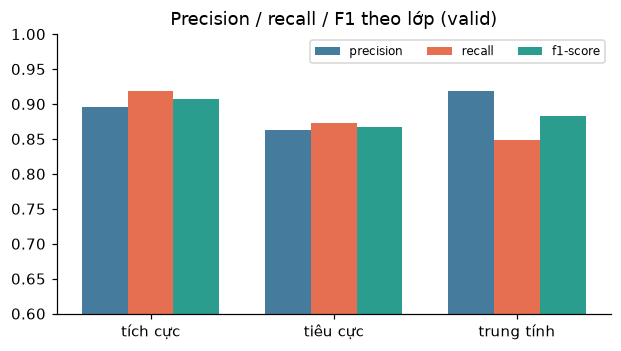

In [3]:
lr = tao_pipe(LogisticRegression(C=10, max_iter=2000)).fit(X_tr, y_tr)
rep = classification_report(y_va, lr.predict(X_va), output_dict=True, zero_division=0)
x = np.arange(len(LABELS)); w = 0.25
fig, ax = plt.subplots(figsize=(6.5, 3.3))
for k, (chi_so, mau) in enumerate([("precision", "#457b9d"), ("recall", "#e76f51"), ("f1-score", "#2a9d8f")]):
    ax.bar(x + (k - 1) * w, [rep[l][chi_so] for l in LABELS], w, label=chi_so, color=mau)
ax.set_xticks(x); ax.set_xticklabels(LABELS); ax.set_ylim(0.6, 1.0); ax.legend(ncol=3, fontsize=8); ax.set_title("Precision / recall / F1 theo lớp (valid)")
plt.show()

**Đọc kết quả.** Chú ý trục y bắt đầu từ 0,6 để thấy chênh lệch (cắt trục có thể gây hiểu lầm, nên luôn ghi rõ). Lớp *trung tính* thường có recall thấp nhất — lớp hiếm nhất bị bỏ sót nhiều nhất.

## Bài tập 3 — Cải thiện `luat_tay`: phủ định và "nhưng"

*Nó có vượt mô hình học máy trên câu khó không? Thế nào là một so sánh công bằng?*

In [4]:
KHEN = ["tốt", "đẹp", "nhanh", "ngon", "rẻ", "hài lòng", "tuyệt", "mượt", "thân thiện", "nhiệt tình", "chu đáo",
        "hợp lý", "bổ ích", "dễ hiểu", "sạch sẽ", "ổn định", "đầy đủ", "chuyên nghiệp", "recommend", "đáng"]
CHE = ["tệ", "kém", "chậm", "dở", "đắt", "thất vọng", "lỗi", "ẩu", "bẩn", "rối", "khó hiểu", "sơ sài",
       "phức tạp", "thờ ơ", "trễ", "treo", "hỏng", "qua loa", "nghèo nàn", "lan man"]
PHU_DINH = r"(?:không|chưa|chẳng|chả)(?:\s+hề)?(?:\s+(?:rất|quá|khá|hơi|thực sự|cực kỳ))?\s+"

def dem(text, tu_dien):
    """Trả về (số lần xuất hiện có phủ định đứng trước, số lần xuất hiện không có phủ định)."""
    bi_phu_dinh = tong = 0
    for w in tu_dien:
        tong += len(re.findall(r"(?<!\w)" + re.escape(w), text))
        bi_phu_dinh += len(re.findall(PHU_DINH + re.escape(w), text))
    return bi_phu_dinh, tong - bi_phu_dinh

def luat_tay_goc(t):
    d = sum(t.count(w) for w in KHEN) - sum(t.count(w) for w in CHE)
    return "tích cực" if d > 0 else "tiêu cực" if d < 0 else "trung tính"

def luat_tay_tot(t):
    if "ưu điểm" in t and "nhược điểm" in t:                 # khuôn "ưu điểm … nhược điểm …" → cân bằng
        return "trung tính"
    ve = t.split(" nhưng ", 1)[1] if " nhưng " in t else t   # vế sau "nhưng" quyết định
    neg_khen, khen = dem(ve, KHEN)
    neg_che, che = dem(ve, CHE)
    diem = (khen + neg_che) - (che + neg_khen)                # 'không + chê' tính là khen; 'không + khen' tính là chê
    return "tích cực" if diem > 0 else "tiêu cực" if diem < 0 else "trung tính"

rows = []
for ten, f in [("luật gốc (Bài 3)", luat_tay_goc), ("luật có phủ định + 'nhưng'", luat_tay_tot)]:
    pv, ph = [f(t) for t in valid["clean"]], [f(t) for t in hard["clean"]]
    rows.append({"hệ thống": ten, "valid macro-F1": round(f1_score(y_va, pv, average="macro"), 3), "câu khó macro-F1": round(f1_score(hard["label"], ph, average="macro"), 3)})
rows.append({"hệ thống": "TF-IDF + LR (1–2-gram)", "valid macro-F1": round(f1_score(y_va, lr.predict(X_va), average="macro"), 3), "câu khó macro-F1": round(hard_f1(tao_pipe(LogisticRegression(C=10, max_iter=2000))), 3)})
pd.DataFrame(rows).set_index("hệ thống")

,valid macro-F1,câu khó macro-F1
hệ thống,,
luật gốc (Bài 3),0.543,0.423
luật có phủ định + 'nhưng',0.646,0.654
TF-IDF + LR (1–2-gram),0.886,0.563


**Đọc kết quả.** Hai quy tắc ngôn ngữ (phủ định, vế sau "nhưng") nâng luật tay từ ≈0,54 lên ≈0,65 macro-F1 trên `valid` và từ ≈0,42 lên ≈0,65 trên **câu khó** — nơi nó thậm chí **vượt TF-IDF + LR (≈0,56)**, vì mô hình học máy thiếu mẫu phủ định trong dữ liệu huấn luyện. Nhưng trên `valid` (cùng phân phối huấn luyện) luật vẫn kém xa LR (≈0,65 so với ≈0,89). Bài học: **tri thức ngôn ngữ của con người có thể bù chỗ dữ liệu thiếu**; luật + học máy kết hợp (ví dụ đưa đặc trưng "phủ định + từ khen" vào mô hình) thường tốt hơn riêng lẻ.

**So sánh công bằng nghĩa là gì?** Luật được viết sau khi *đã biết* các dạng câu khó (phủ định, "nhưng") — tức là người viết luật đã "nhìn" tập kiểm tra theo nghĩa kiến thức. Để công bằng: (1) chỉ được chỉnh luật/từ khóa bằng **train + valid**, không nhìn tập khó; (2) cho mô hình học máy cùng lượng *công sức thiết kế* (ví dụ thêm đặc trưng phủ định); (3) báo cáo luật và mô hình trên **một tập kiểm tra mới, chưa ai nhìn**.

## Bài tập 4 — Mục 11 với 3 random_state khác nhau: thứ hạng có ổn định không?

In [5]:
PHU_DINH_BO = r"\b(không|chưa|chẳng|hề)\b"
bien_the = {
    "chỉ hạ chữ thường": lambda t: t.lower(),
    "normalize": lambda t: normalize(t),
    "normalize + bỏ dấu": lambda t: strip_accents(normalize(t)),
    "normalize + xóa phủ định": lambda t: re.sub(PHU_DINH_BO, " ", normalize(t)),
}
bang = {}
for rs in [0, 1, 2]:
    cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=rs)
    bang[f"random_state={rs}"] = {ten: cross_val_score(tao_pipe(LogisticRegression(C=10, max_iter=2000), preprocessor=fn), train["text"], y_tr, cv=cv_r, scoring="f1_macro").mean()
                                  for ten, fn in bien_the.items()}
B = pd.DataFrame(bang)
display(B.round(3))
display(B.rank(ascending=False).astype(int).rename(columns=lambda c: "hạng " + c))

,random_state=0,random_state=1,random_state=2
chỉ hạ chữ thường,0.862,0.864,0.866
normalize,0.860,0.864,0.866
normalize + bỏ dấu,0.881,0.882,0.880
normalize + xóa phủ định,0.835,0.841,0.844


,hạng random_state=0,hạng random_state=1,hạng random_state=2
chỉ hạ chữ thường,2,3,3
normalize,3,2,2
normalize + bỏ dấu,1,1,1
normalize + xóa phủ định,4,4,4


**Đọc kết quả.** Hai kết luận **ổn định** qua cả ba cách chia: **"bỏ dấu" luôn đứng đầu** (≈0,88) và **"xóa phủ định" luôn đứng cuối** (≈0,84). Hai biến thể ở giữa (chỉ hạ chữ thường vs `normalize`) **đảo thứ hạng** qua lại — chênh lệch giữa chúng (≈0,002) nhỏ hơn nhiễu của cách chia, nên **không** nên nói biến thể nào hơn. Đó là cách phân biệt chênh lệch *thật* với chênh lệch *do may rủi*: chỉ tin những xếp hạng không đổi khi bạn đổi cách chia dữ liệu.

## Bài tập 5 (khó) — Sửa/loại nhãn nghi sai rồi huấn luyện lại

Ta không có người gán nhãn, nên **mô phỏng** quy trình rà soát bằng hai can thiệp tự động: (a) **loại bỏ** k mẫu nghi sai nhất; (b) **đổi nhãn** của chúng thành nhãn mô hình đoán (đại diện cho quyết định của một người xem xét đồng ý với mô hình). Đây chỉ là *mô phỏng*; ở dự án thật bạn phải đọc từng mẫu.

In [6]:
clf0 = tao_pipe(LogisticRegression(C=10, max_iter=2000))
oof = cross_val_predict(clf0, X_tr, y_tr, cv=cv, method="predict_proba")
classes = np.array(sorted(LABELS))
pred_oof, conf = classes[oof.argmax(1)], oof.max(1)
nghi = np.where(pred_oof != y_tr.values)[0]
nghi = nghi[np.argsort(-conf[nghi])]                      # nghi sai nhất đứng đầu

def danh_gia(y_moi, mask=None):
    Xm = X_tr if mask is None else X_tr[mask]
    ym = y_moi if mask is None else y_moi[mask]
    m = tao_pipe(LogisticRegression(C=10, max_iter=2000)).fit(Xm, ym)
    return round(f1_score(y_va, m.predict(X_va), average="macro"), 3), round(f1_score(hard["label"], m.predict(hard["clean"]), average="macro"), 3)

rows = [{"can thiệp": "gốc (không sửa)", "k": 0, "valid macro-F1": danh_gia(y_tr.values)[0], "câu khó macro-F1": danh_gia(y_tr.values)[1]}]
for k in [10, 50, 100]:
    top_k = nghi[:k]
    mask = np.ones(len(y_tr), dtype=bool); mask[top_k] = False
    f_loai = danh_gia(y_tr.values, mask)
    y_sua = y_tr.values.copy(); y_sua[top_k] = pred_oof[top_k]
    f_sua = danh_gia(y_sua)
    rows.append({"can thiệp": "loại bỏ", "k": k, "valid macro-F1": f_loai[0], "câu khó macro-F1": f_loai[1]})
    rows.append({"can thiệp": "đổi nhãn theo mô hình", "k": k, "valid macro-F1": f_sua[0], "câu khó macro-F1": f_sua[1]})
pd.DataFrame(rows).set_index(["can thiệp", "k"])

,,valid macro-F1,câu khó macro-F1
can thiệp,k,,
gốc (không sửa),0,0.886,0.563
loại bỏ,10,0.873,0.609
đổi nhãn theo mô hình,10,0.876,0.583
loại bỏ,50,0.887,0.537
đổi nhãn theo mô hình,50,0.894,0.537
loại bỏ,100,0.872,0.495
đổi nhãn theo mô hình,100,0.851,0.476


**Đọc kết quả.** (Số của bạn có thể lệch nhẹ.) Điểm trên `valid` **dao động trong nhiễu** quanh 0,87–0,89: ta chỉ chạm tối đa 100/1.262 mẫu và `valid` *cũng chứa nhãn nhiễu* nên điểm bị chặn. Điều bất ngờ nằm ở **câu khó**: khi k tăng, điểm câu khó *giảm* (từ ≈0,56 xuống ≈0,48–0,50 ở k = 100). Lý do: tập "nghi sai nhất" lẫn nhiều mẫu **khó nhưng đúng** (như phủ định, đối lập) — mô hình nghi ngờ vì nó chưa hiểu chúng, không phải vì nhãn sai. Loại hay đổi nhãn chúng làm mô hình mất đúng loại tín hiệu cần để xử lý ca khó. Hai bài học: (1) "sửa nhãn theo mô hình" là vòng lặp tự xác nhận — nó củng cố điều mô hình đã tin; (2) nhãn nghi sai cần được **người** xem xét độc lập, phân biệt *nhãn sai* với *ca khó*.

**Vì sao không bao giờ sửa nhãn của tập `test`?** Test là thước đo *độc lập*. Nếu bạn sửa nhãn test sau khi đã thấy mô hình dự đoán gì, bạn đang điều chỉnh thước đo theo mô hình — điểm số hết ý nghĩa. Nếu phát hiện nhãn test sai, hãy làm một *phiên bản test mới* có ghi lại thay đổi và đánh giá lại **mọi** mô hình trên phiên bản đó.